In [1]:
import matplotlib.pyplot as plt
import numpy as np
# import cv2 as cv
import pandas as pd
import anndata as ad
import os,sys,re
import seaborn as sns



In [3]:
# parse images
img_dir = '/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_Rep1-RawMorphologyImages/'
files = sorted([f for f in os.listdir(img_dir)])
print(len(files)/9)
img_df = pd.DataFrame({'filename':files})
img_df['Run_Tissue_name'] = img_dir.split('/')[-3]
img_df['fov'] = img_df['filename'].apply(lambda x: int(x.split('.')[0].split('_')[-2][1:]))
img_df['z'] = img_df['filename'].apply(lambda x: int(x.split('.')[0].split('_')[-1][1:]))
img_df['filepath'] = img_df['filename'].apply(lambda x: os.path.join(img_dir,x))
img_df.head()

32.0


,filename,Run_Tissue_name,fov,z,filepath
0,20210907_180607_S1_C902_P99_N99_F001_Z001.TIF,Lung5_Rep1,1,1,/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_R...
1,20210907_180607_S1_C902_P99_N99_F001_Z002.TIF,Lung5_Rep1,1,2,/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_R...
2,20210907_180607_S1_C902_P99_N99_F001_Z003.TIF,Lung5_Rep1,1,3,/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_R...
3,20210907_180607_S1_C902_P99_N99_F001_Z004.TIF,Lung5_Rep1,1,4,/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_R...
4,20210907_180607_S1_C902_P99_N99_F001_Z005.TIF,Lung5_Rep1,1,5,/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_R...


In [ ]:
# # parse images
# img_dir = '/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/CellComposite'
# # img_dir = '/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/CompartmentLabels'
# # img_dir = '/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/CellOverlay'

# files = sorted([f for f in os.listdir(img_dir) if f.endswith(('.png','.tif','.jpg'))])
# img_df = pd.DataFrame({'filename':files})
# img_df['Run_Tissue_name'] = img_dir.split('/')[-3]
# img_df['fov'] = img_df['filename'].apply(lambda x: int(x.split('.')[0].split('_')[1][1:]))
# img_df['filepath'] = img_df['filename'].apply(lambda x: os.path.join(img_dir,x))
# img_df.head()


,filename,Run_Tissue_name,fov,filepath
0,CellComposite_F001.jpg,Lung5_Rep1,1,/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_R...
1,CellComposite_F002.jpg,Lung5_Rep1,2,/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_R...
2,CellComposite_F003.jpg,Lung5_Rep1,3,/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_R...
3,CellComposite_F004.jpg,Lung5_Rep1,4,/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_R...
4,CellComposite_F005.jpg,Lung5_Rep1,5,/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_R...


In [84]:
import pickle
import sys
sys.path.append('/home/jwinchel/Heimdall/')

from Heimdall.utils import convert_to_ensembl_ids
# load transcript data
tx_df = pd.read_csv('/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/Lung5_Rep1_tx_file.csv')

# Unpickling (loading from a file)
with open('/home/jwinchel/Syndri/nsclc_playground/gene_mapping.pickle', 'rb') as f:
    gene_mapping = pickle.load(f)


tx_df['gene_id_ensembl'] = tx_df['target'].map(gene_mapping.mapping_full)
tx_df['gene_id_ensembl'] = tx_df['gene_id_ensembl'].apply(lambda x: x[0] if isinstance(x,list) else x)
cell_df = pd.read_csv('/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/Lung5_Rep1_metadata_file.csv')
st_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/processed_adata/ST_NSCLC_labeltransfer_consolidated_withprobs.h5ad')
l5r1_metadata = pd.read_csv('/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/Lung5_Rep1_metadata_file.csv')

st_data = st_data[st_data.obs['Run_Tissue_name']=='Lung5_Rep1']
st_data.obs = st_data.obs.merge(l5r1_metadata[['fov','cell_ID','CenterX_local_px',
       'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px']],on=['fov','cell_ID'])
st_data.obs['cell_type'] = st_data.obs['cell_type'].astype(str)
st_data.obs.loc[st_data.obs['cell_type'].str.startswith('tumor'),'cell_type'] = 'tumor'

# load a single fov
tx_df = tx_df[tx_df['fov'] == 3].reset_index(drop=True)
cell_df = cell_df[cell_df['fov'] == 3].reset_index(drop=True)
cell_df.head()

,fov,cell_ID,Area,AspectRatio,CenterX_local_px,CenterY_local_px,CenterX_global_px,CenterY_global_px,Width,Height,Mean.MembraneStain,Max.MembraneStain,Mean.PanCK,Max.PanCK,Mean.CD45,Max.CD45,Mean.CD3,Max.CD3,Mean.DAPI,Max.DAPI
0,3,1,1390,0.96,1363,3624,15496.333333,158840.666667,47,49,4854,8927,7157,43824,421,1117,0,77,5910,32127
1,3,2,15811,1.89,600,3593,14733.333333,158809.666667,208,110,2705,10853,17048,55879,252,743,0,174,1257,18005
2,3,3,2543,1.38,3071,3623,17204.333333,158839.666667,69,50,3455,9061,644,1158,236,601,0,69,4864,30481
3,3,4,4223,1.61,3335,3616,17468.333333,158832.666667,103,64,5645,24655,845,4804,348,1198,86,1097,658,23719
4,3,5,2694,1.51,3387,3624,17520.333333,158840.666667,74,49,2551,7178,7317,62237,262,571,0,1,13396,46194


In [87]:
from scipy import sparse
def gene_cell_admix_df(
    adata,
    probs_layer="admix_probs",
    thr=0.5,
    use_nonzero_only=True,
):
    """
    Returns a long dataframe with columns:
      cell, gene, prob, is_admixed, status
    If use_nonzero_only=True, restrict to entries where X > 0 (i.e., observed transcripts).
    """
    probs = adata.layers[probs_layer]
    if sparse.issparse(probs):
        probs = probs.toarray()

    X = adata.X
    if sparse.issparse(X):
        X = X.tocsr()

    cells = np.asarray(adata.obs_names)
    genes = np.asarray(adata.var_names)

    if use_nonzero_only:
        if not sparse.issparse(adata.X):
            nz = np.nonzero(X)
            r, c = nz
        else:
            r, c = X.nonzero()

        df = pd.DataFrame({
            "cell": adata.obs['cell_ID'].values[r],
            "fov": adata.obs['fov'].values[r],
            "gene": genes[c],
            "prob": probs[r, c],
            "cell_type": adata.obs['cell_type'].values[r],
        })
    else:
        # WARNING: can be huge (n_cells * n_genes)
        r, c = np.indices(probs.shape)
        df = pd.DataFrame({
            "cell": cells[r.ravel()],
            "gene": genes[c.ravel()],
            "prob": probs.ravel(),
        })

    df["is_admixed"] = df["prob"] > thr
    df["status"] = np.where(df["is_admixed"], "admixed", "kept")
    return df

gene_cell_df = gene_cell_admix_df(st_data, probs_layer="admix_probs", thr=0.674, use_nonzero_only=True)

In [88]:
gene_cell_df.head()

,cell,fov,gene,prob,cell_type,is_admixed,status
0,1.0,1.0,ENSG00000019582,0.000000,DC,False,kept
1,1.0,1.0,ENSG00000060138,0.000000,DC,False,kept
2,1.0,1.0,ENSG00000069493,0.000000,DC,False,kept
3,1.0,1.0,ENSG00000090104,0.752824,DC,True,admixed
4,1.0,1.0,ENSG00000107738,0.734360,DC,True,admixed


In [89]:
tx_df = tx_df.merge(gene_cell_df, left_on=['fov','cell_ID','gene_id_ensembl'], right_on=['fov','cell','gene'], how='left')

In [90]:
tx_df['cell_type'] = tx_df['cell_type'].fillna('unknown')
tx_df['status'] = tx_df['status'].fillna('unknown')

/tmp/ipykernel_1210922/2463284550.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  _ = ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment='right')


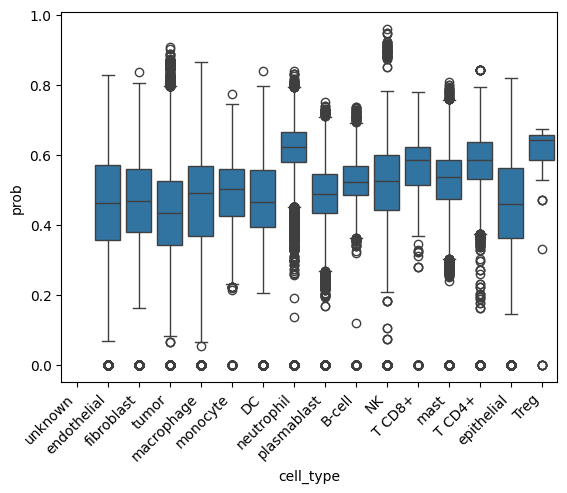

In [91]:
ax = sns.boxplot(data=tx_df,x='cell_type',y='prob')
_ = ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment='right')

/tmp/ipykernel_1105160/2000698115.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  _ = ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment='right')


Text(0.5, 1.0, 'Enrichment of transcript admixture probabilities among cell compartments,\nby cell type (admixed only)')

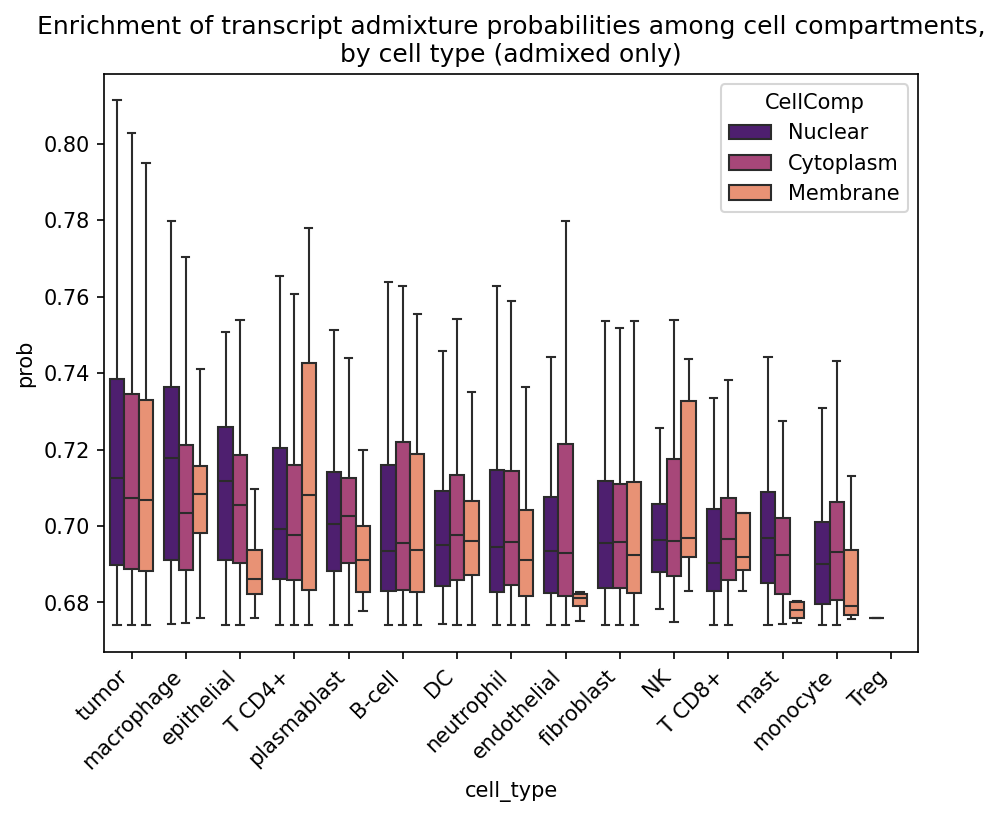

In [25]:
fig,ax = plt.subplots(figsize=(7,5),dpi=150)
comp_enrich = tx_df[tx_df['status'] == "admixed"].groupby(['cell_type','cell_ID','CellComp','gene'])['prob'].mean().reset_index()
ct_order = comp_enrich.groupby('cell_type')['prob'].mean().sort_values(ascending=False).index
sns.boxplot(data=comp_enrich,x='cell_type',y='prob',hue='CellComp',ax=ax,showfliers=False,order=ct_order,hue_order=['Nuclear','Cytoplasm','Membrane'],palette='magma')
# sns.boxplot(data=tx_df[tx_df['status'] == "admixed"],x='cell_type',y='prob',hue='CellComp',ax=ax,showfliers=False)

# ax.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
_ = ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment='right')
ax.set_title("Enrichment of transcript admixture probabilities among cell compartments,\nby cell type (admixed only)")

/tmp/ipykernel_1210922/2019401402.py:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  _ = ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment="right")


Text(0, 0.5, 'Fraction of admixed transcripts (per gene)')

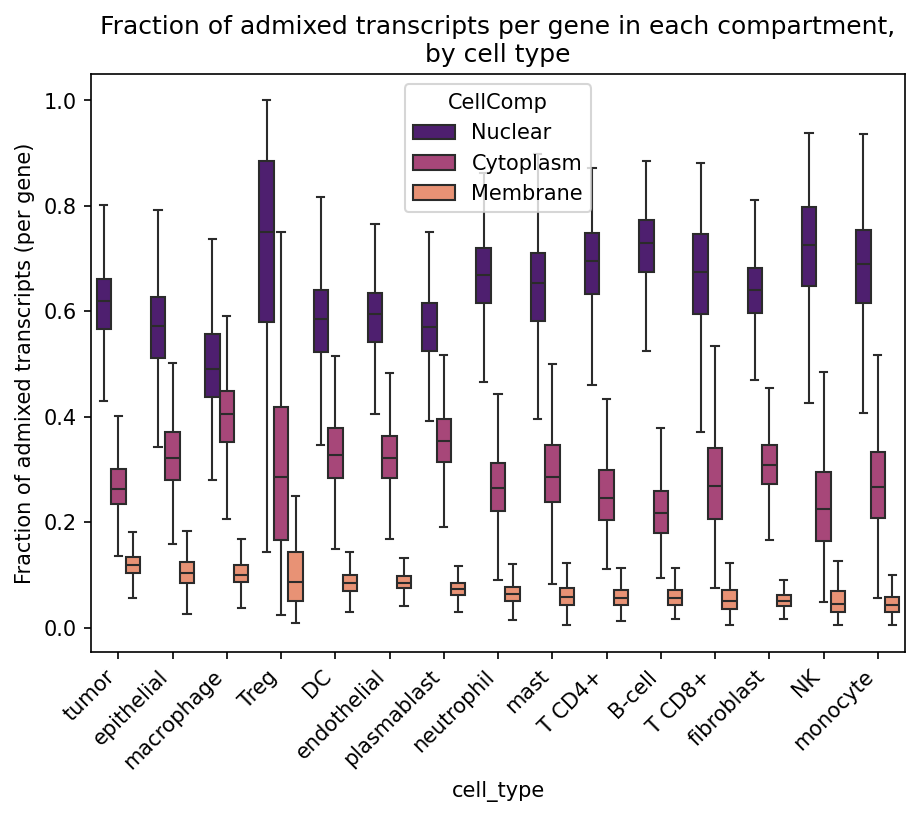

In [20]:
fig, ax = plt.subplots(figsize=(7,5), dpi=150)

# Keep only admixed transcripts
admix_tx = tx_df[tx_df["status"] == "kept"].copy()

# Count transcripts per (cell_type, gene, compartment)
gene_comp_counts = (
    admix_tx
    .groupby(["cell_type", "gene", "CellComp"])
    .size()
    .reset_index(name="n_tx")
)

# Total admixed transcripts per (cell_type, gene)
gene_totals = (
    gene_comp_counts
    .groupby(["cell_type", "gene"])["n_tx"]
    .sum()
    .reset_index(name="gene_total_tx")
)

# Merge totals
gene_comp_counts = gene_comp_counts.merge(
    gene_totals,
    on=["cell_type", "gene"],
    how="left"
)

# Compute fraction of that gene’s admixed transcripts in each compartment
gene_comp_counts["fraction"] = (
    gene_comp_counts["n_tx"] / gene_comp_counts["gene_total_tx"]
)

# Order cell types by mean fraction (optional)
ct_order = (
    gene_comp_counts[gene_comp_counts["CellComp"] == 'Membrane']
    .groupby("cell_type")["fraction"]
    .median()
    .sort_values(ascending=False)
    .index
)

# Plot
sns.boxplot(
    data=gene_comp_counts,
    x="cell_type",
    y="fraction",
    hue="CellComp",
    ax=ax,
    showfliers=False,
    order=ct_order,
    hue_order=["Nuclear","Cytoplasm","Membrane"],
    palette="magma"
)

_ = ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment="right")
ax.set_title(
    "Fraction of admixed transcripts per gene in each compartment,\nby cell type"
)
ax.set_ylabel("Fraction of admixed transcripts (per gene)")

In [86]:
tx_df[tx_df['status'] == "unknown"].groupby(['cell_type'])

KeyError: 'status'

In [53]:
tx_df['status'].value_counts()

status
kept       1410953
admixed      35745
Name: count, dtype: int64

/tmp/ipykernel_1210922/1339736012.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  _ = ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment="right")


Text(0, 0.5, 'Δ fraction within gene (admixed − non-admixed)')

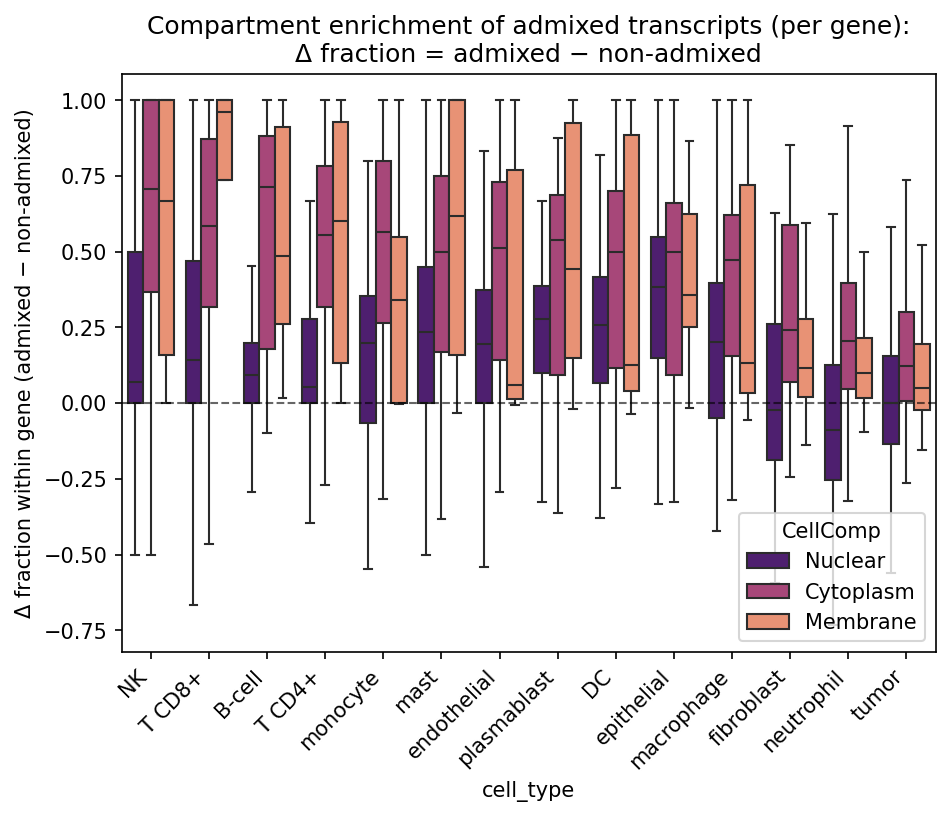

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(7,5), dpi=150)

# Define status groups: admixed vs not
df = tx_df[tx_df["status"].isin(["admixed", "kept"])].copy()
df["is_admixed"] = (df["status"] == "admixed")

# Counts per (cell_type, gene, compartment, is_admixed)
counts = (
    df.groupby(["cell_type", "gene", "CellComp", "is_admixed"])
      .size()
      .reset_index(name="n_tx")
)

# Totals per (cell_type, gene, is_admixed)
totals = (
    counts.groupby(["cell_type", "gene", "is_admixed"])["n_tx"]
          .sum()
          .reset_index(name="total_tx")
)

counts = counts.merge(totals, on=["cell_type", "gene", "is_admixed"], how="left")
counts["frac"] = counts["n_tx"] / counts["total_tx"]

# Pivot to get admixed and non-admixed fractions side-by-side
wide = (
    counts.pivot_table(
        index=["cell_type", "gene", "CellComp"],
        columns="is_admixed",
        values="frac",
        fill_value=0.0
    )
    .reset_index()
    .rename(columns={False: "frac_not_admixed", True: "frac_admixed"})
)

# Keep only genes that actually have some admixed transcripts
wide = wide[wide["frac_admixed"] > 0].copy()

# Enrichment: admixed fraction minus baseline fraction
wide["delta_frac"] = wide["frac_admixed"] - wide["frac_not_admixed"]

# Order cell types by mean cytoplasm/membrane enrichment (optional)
ct_order = (
    wide[wide["CellComp"].isin(["Cytoplasm", "Membrane"])]
    .groupby("cell_type")["delta_frac"]
    .mean()
    .sort_values(ascending=False)
    .index
)

sns.boxplot(
    data=wide,
    x="cell_type",
    y="delta_frac",
    hue="CellComp",
    order=ct_order,
    hue_order=["Nuclear", "Cytoplasm", "Membrane"],
    showfliers=False,
    palette="magma",
    ax=ax
)

ax.axhline(0, ls="--", lw=1, color="black", alpha=0.6)
_ = ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment="right")
ax.set_title("Compartment enrichment of admixed transcripts (per gene):\nΔ fraction = admixed − non-admixed")
ax.set_ylabel("Δ fraction within gene (admixed − non-admixed)")

In [31]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import sparse

def plot_total_transcripts_per_cell(
    adata,
    cell_type_key="cell_type",
    figsize=(8,5),
    dpi=150,
    log_scale=False,
    showfliers=False
):
    """
    Plot distribution of total transcript counts per cell,
    stratified by cell type.
    """

    # --- compute total transcripts per cell ---
    X = adata.X
    
    if sparse.issparse(X):
        totals = np.asarray(X.sum(axis=1)).ravel()
    else:
        totals = X.sum(axis=1)
    print(len(totals), len(adata.obs))
    df = pd.DataFrame({
        "cell_type": adata.obs[cell_type_key].values,
        "total_transcripts": totals
    })

    # optional ordering by median
    ct_order = (
        df.groupby("cell_type")["total_transcripts"]
          .median()
          .sort_values(ascending=False)
          .index
    )

    # --- plot ---
    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)

    sns.boxplot(
        data=df,
        x="cell_type",
        y="total_transcripts",
        order=ct_order,
        showfliers=showfliers,
        ax=ax
    )

    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set_title("Distribution of total transcripts per cell")
    ax.set_ylabel("Total transcripts per cell")

    if log_scale:
        ax.set_yscale("log")

    plt.tight_layout()
    plt.show()

    return df

98002 98002


/tmp/ipykernel_1210922/2080028145.py:53: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


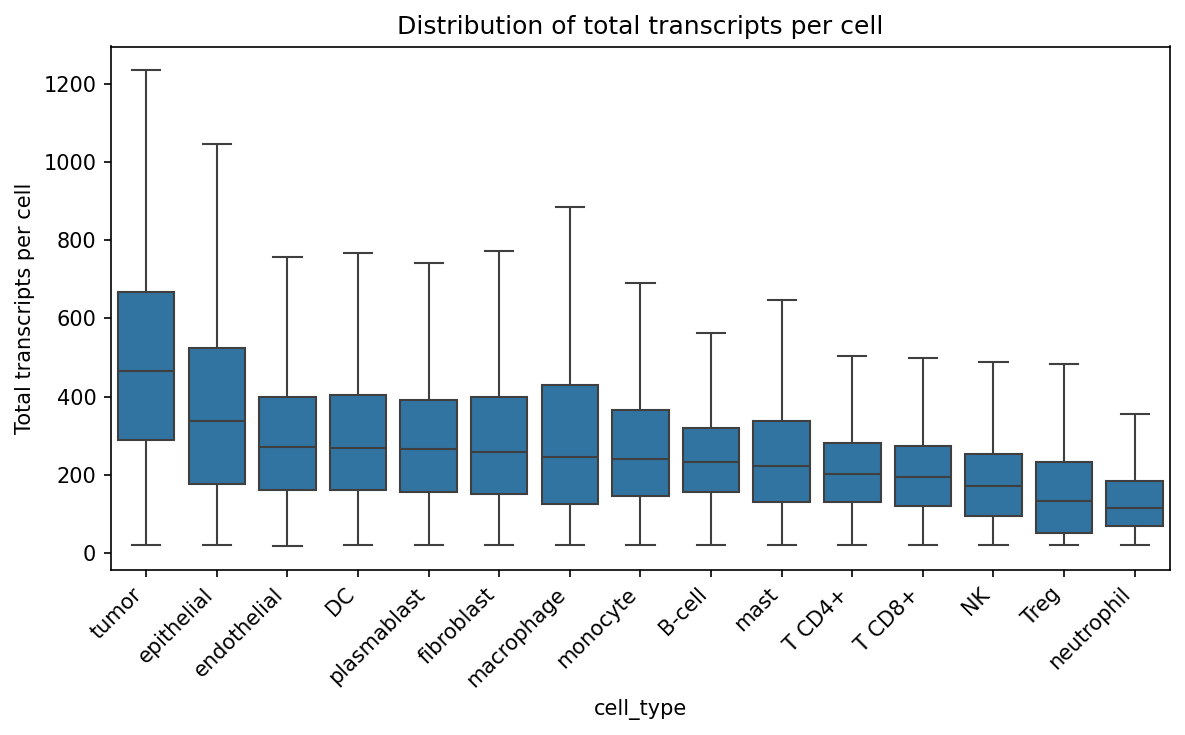

,cell_type,total_transcripts
0,DC,23.0
1,endothelial,26.0
2,endothelial,74.0
3,DC,60.0
4,macrophage,52.0
...,...,...
97997,DC,47.0
97998,fibroblast,95.0
97999,DC,82.0
98000,B-cell,24.0


In [32]:
plot_total_transcripts_per_cell(st_data, log_scale=False)

In [44]:
tx_df['z'].dtype

dtype('int64')

In [92]:
cell_df = cell_df[(cell_df['CenterX_local_px']>50) & 
        (cell_df['CenterY_local_px']>50) &
        (cell_df['CenterX_local_px']<5322) &
        (cell_df['CenterY_local_px']<5322)].reset_index(drop=True)

In [93]:
tx_df = tx_df[tx_df['CellComp']!='0'].reset_index(drop=True)
tx_df['status'].value_counts()

status
kept       1011720
admixed      77146
unknown      58180
Name: count, dtype: int64

In [94]:
ranked_admix = tx_df[tx_df['status']=='admixed'].groupby(['cell_type','fov','cell_ID','status']).size().reset_index(name='admix_tx_count').sort_values(by='admix_tx_count', ascending=False)
k = 4

admix_counts = (
    tx_df.loc[tx_df["status"] == "admixed"]
      .groupby(["cell_type", "fov", "cell_ID"], as_index=False)
      .size()
      .rename(columns={"size": "admix_tx_count"})
)

med = (
    admix_counts.groupby(["cell_type", "fov"], as_index=False)["admix_tx_count"]
    .median()
    .rename(columns={"admix_tx_count": "median_admix_tx_count"})
)

closest_to_median = (
    admix_counts.merge(med, on=["cell_type", "fov"], how="left")
      .assign(dist_to_median=lambda d: (d["admix_tx_count"] - d["median_admix_tx_count"]).abs())
      .sort_values(["cell_type", "fov", "dist_to_median", "admix_tx_count"])
      .groupby(["cell_type", "fov"], as_index=False)
      .head(k)
)

closest_to_median

,cell_type,fov,cell_ID,admix_tx_count,median_admix_tx_count,dist_to_median
2,B-cell,3,700,13,13.0,0.0
5,B-cell,3,1392,16,13.0,3.0
6,B-cell,3,2055,7,13.0,6.0
0,B-cell,3,175,20,13.0,7.0
7,DC,3,35,28,28.5,0.5
19,DC,3,1905,29,28.5,0.5
23,DC,3,2025,29,28.5,0.5
9,DC,3,215,30,28.5,1.5
40,NK,3,1677,22,22.0,0.0
47,NK,3,2389,19,22.0,3.0


In [58]:
sample_df = tx_df[tx_df['cell_ID'].isin([1715,2875])]

In [95]:
# getting cells from kharchenko fig 4c
sample_cells = cell_df.merge(closest_to_median.groupby('cell_type').head(5)[['cell_type','fov','cell_ID']], on=['fov','cell_ID'], how='inner')
# sample_cells = cell_df[cell_df['cell_ID'].isin([1715,2875])].reset_index(drop=True)

In [96]:
sample_cells.groupby('cell_type').size()

cell_type
B-cell         4
DC             3
NK             4
T CD4+         4
T CD8+         3
endothelial    4
epithelial     4
fibroblast     2
macrophage     3
mast           3
monocyte       4
neutrophil     4
plasmablast    2
tumor          3
dtype: int64

In [62]:
sample_cells = sample_cells[sample_cells['cell_type'].isin(['tumor','neutrophil','B-cell','T CD4+','epithelial'])]

In [97]:
tx_df[(tx_df['cell_type']=='macrophage')&(tx_df['status']=='kept')]['target'].value_counts()

target
DUSP5     3090
PSAP      2569
MZT2A     2171
CD74      1497
HLA-B     1202
          ... 
ADGRG5       2
NRIP3        1
IL2RB        1
RSPO2        1
NRXN3        1
Name: count, Length: 954, dtype: int64

<Axes: xlabel='prob', ylabel='Count'>

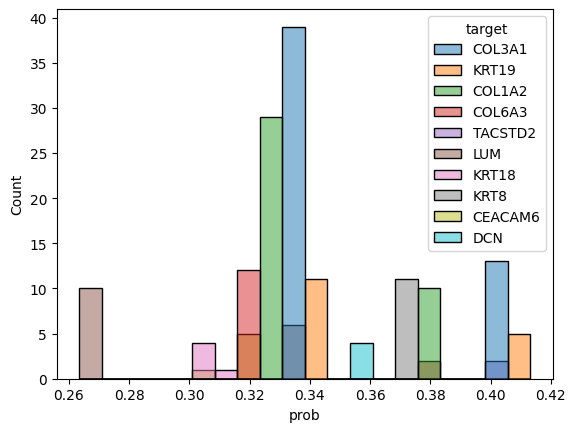

In [81]:
# sample_cells[sample_cells['cell_type']=='tumor']['fov'].value_counts()
# sample_df
sample_df.loc[sample_df['prob']>0.5,'status'] = 'admixed'
marker_genes = ['KRT8','KRT19','KRT18','TACSTD2','CEACAM6',
                'LUM','DCN','COL1A2','COL3A1','COL6A3',
                'C1QA','MRC1','C1QB','CD163','OLR1']

sns.histplot(data=sample_df[sample_df['target'].isin(marker_genes)], x='prob', hue='target', bins=20, )

In [36]:
sample_cells

,fov,cell_ID,Area,AspectRatio,CenterX_local_px,CenterY_local_px,CenterX_global_px,CenterY_global_px,Width,Height,...,Max.MembraneStain,Mean.PanCK,Max.PanCK,Mean.CD45,Max.CD45,Mean.CD3,Max.CD3,Mean.DAPI,Max.DAPI,cell_type
1,26,62,3739,0.52,1460,3570,4648.888889,177036.666667,53,101,...,5491,39246,65314,354,1090,0,141,1896,14583,tumor
2,26,187,1386,0.73,4532,3421,7720.888889,176887.666667,36,49,...,3825,685,1032,283,595,0,0,2671,11398,epithelial
3,26,193,3823,0.91,2366,3399,5554.888889,176865.666667,67,74,...,20867,923,2791,3596,29076,3,466,5316,32593,neutrophil
5,26,278,2618,1.13,165,3289,3353.888889,176755.666667,61,54,...,3433,1639,4877,292,689,0,214,0,0,tumor
6,26,364,2225,0.83,4587,3149,7775.888889,176615.666667,48,58,...,4390,817,2108,271,781,0,36,0,376,epithelial
7,26,410,2882,1.00,1009,3077,4197.888889,176543.666667,62,62,...,6900,6725,29808,275,710,26,412,0,127,T CD4+
9,26,619,1622,1.59,1564,2753,4752.888889,176219.666667,62,39,...,4691,2171,11020,319,659,16,414,12268,37368,B-cell
14,26,847,3460,1.01,3264,2377,6452.888889,175843.666667,96,95,...,12543,1195,20734,408,1594,115,1191,8902,34145,neutrophil
15,26,964,1267,0.59,643,2222,3831.888889,175688.666667,32,54,...,3981,849,2244,424,841,169,667,3546,17082,T CD4+
17,26,1018,1629,0.75,5290,2137,8478.888889,175603.666667,44,59,...,3624,26446,56033,309,624,0,74,10767,18399,tumor


In [61]:
img_df.groupby(['fov','z']).size().max()

1

In [103]:
valid_cts = sample_cells.groupby('cell_type').size()>=4    
valid_cts = valid_cts[valid_cts].index.tolist()
sorted(valid_cts)

['B-cell',
 'NK',
 'T CD4+',
 'endothelial',
 'epithelial',
 'monocyte',
 'neutrophil']

In [ ]:
tx_df['']

(5, 3648, 5472)
[1, 2, 3, 4, 5, 6, 7, 8, 9]


7 4


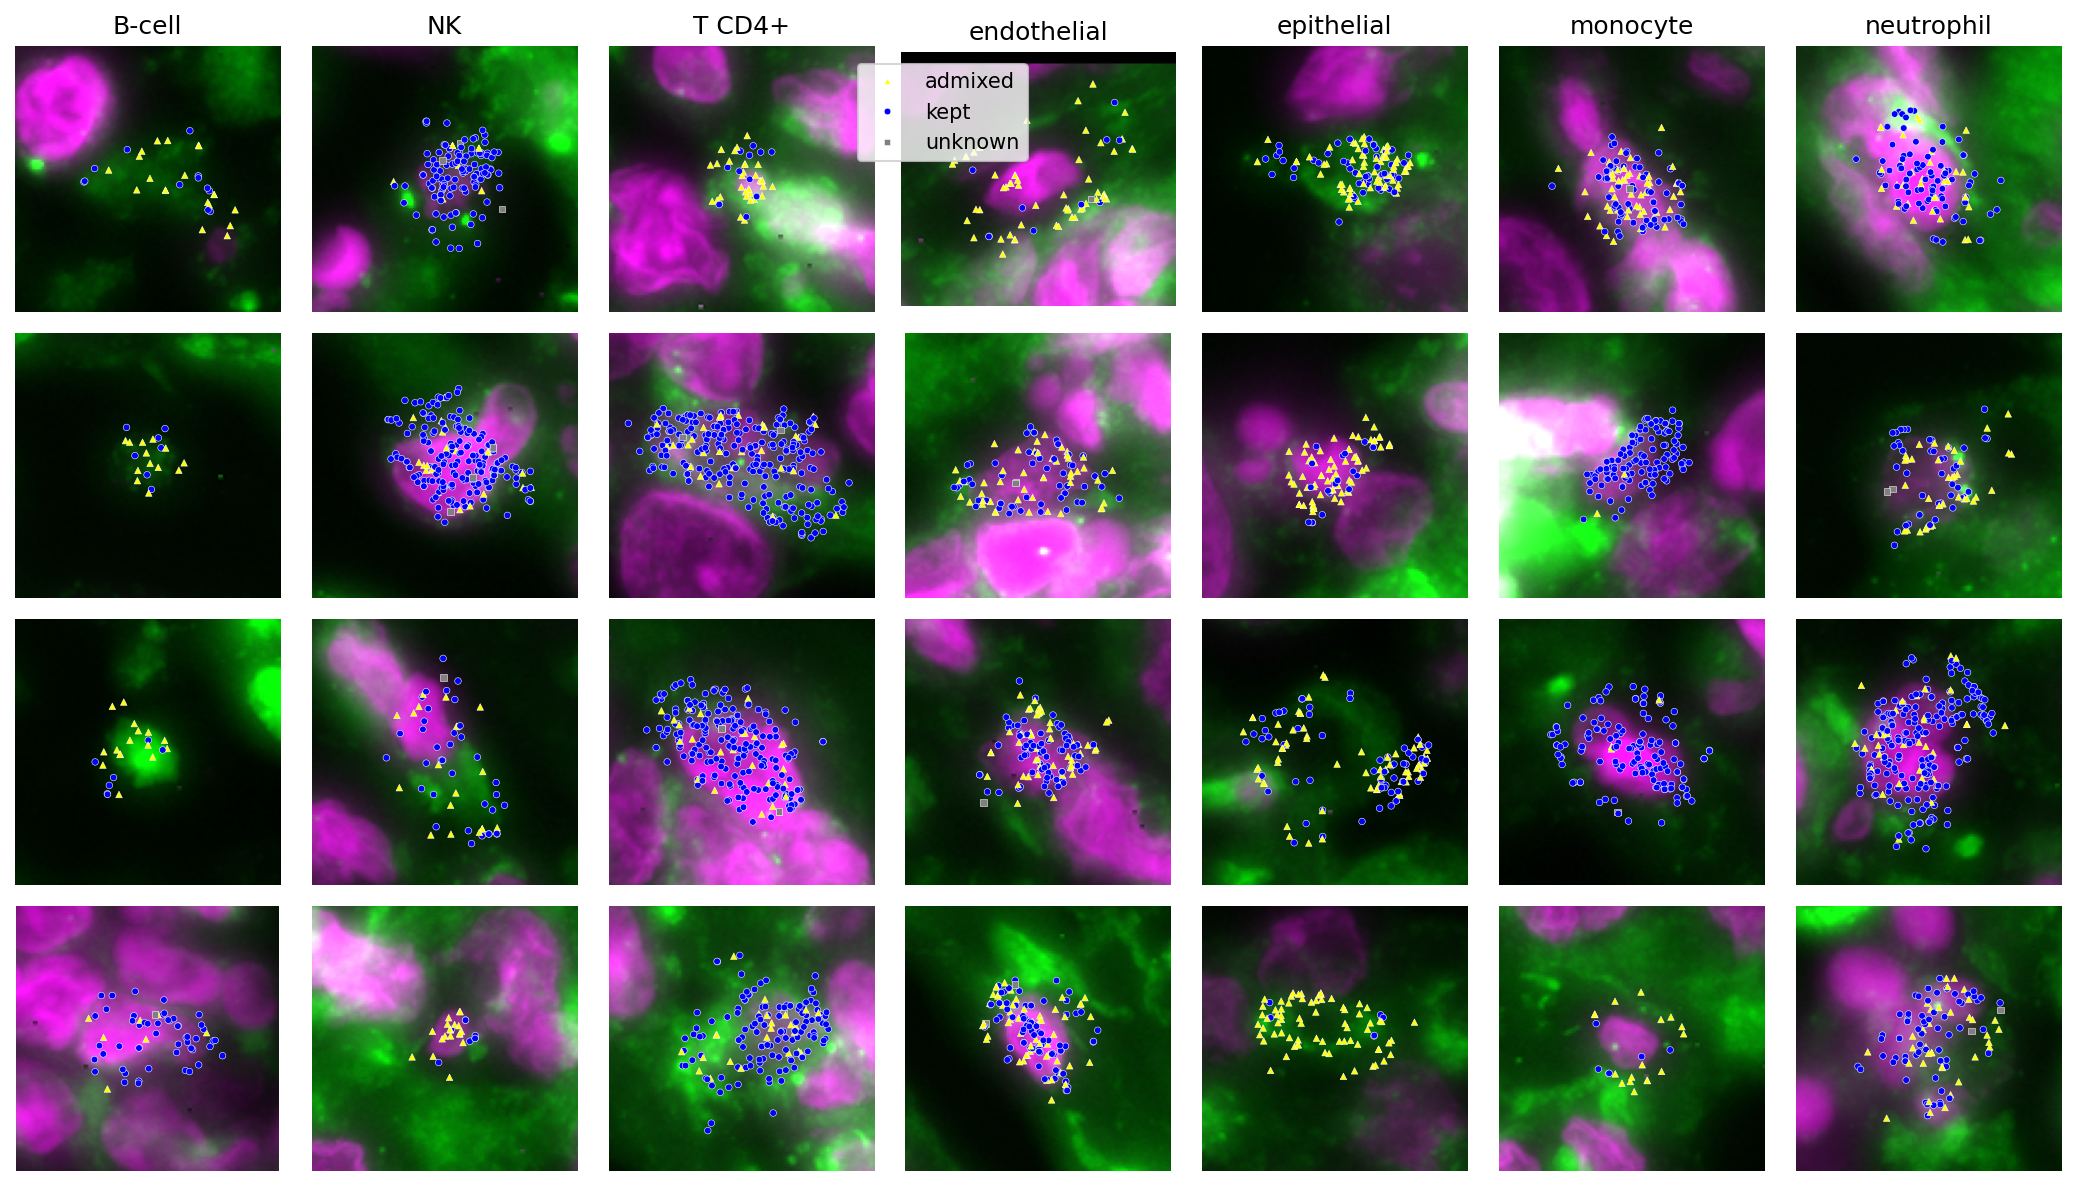

In [106]:
import tifffile
import importlib
import sys
from plotting import plot_cell_crops_with_tx, load_z_projected_image
importlib.reload(sys.modules['plotting'])
raw = tifffile.imread(img_df[img_df["fov"] == 26].iloc[3]["filepath"])  # (C,H,W)
print(raw.shape)
raw = load_z_projected_image(img_df,fov=3)
#
marker_dict = {'admixed':'^','kept':'o','unknown':'s'}
palette_dict = {'admixed':'yellow','kept':'blue','unknown':'gray'}
fig, axes = plot_cell_crops_with_tx(
    raw,
    cell_df=sample_cells[sample_cells['cell_type'].isin(valid_cts)],
    tx_df=tx_df,
    n_cells=28,
    ncols=7,
    crop_size=110,
    label_col="status",
    ch_purple=4,
    ch_green=0,
    y_origin="bottom",   
    s=10,
    random_state=None,
    dpi=150,
    figsize=(14,8),
    markers=marker_dict,
    palette=palette_dict,
)
# fig.legend(handles, labels, loc="upper center", ncol=2, frameon=True)
fig.tight_layout()
